In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Best hyperparameters heatmap

In [2]:
# Simulate 60 rows of results
np.random.seed(42)
n_rows = 60

# The metrics we are "testing/showing"
all_metrics_df = pd.DataFrame({
    "learning_rate": np.random.choice([0.001, 0.003, 0.005], size=n_rows),
    "dropout_rate": np.random.choice([0.2, 0.3], size=n_rows),
    "batch_size": np.random.choice([32, 128], size=n_rows),
})

# Simulate accuracy for intra and cross / generate random data
for i in ["Intra", "Cross"]:
    all_metrics_df[f"test_{i}_accuracy"] = np.random.uniform(60, 100, size=n_rows)

print(all_metrics_df)

    learning_rate  dropout_rate  batch_size  test_Intra_accuracy  \
0           0.005           0.3          32            80.342828   
1           0.001           0.2          32            96.302659   
2           0.005           0.3          32            69.971689   
3           0.005           0.3         128            76.415317   
4           0.001           0.3          32            90.222046   
5           0.001           0.3          32            69.151927   
6           0.005           0.3          32            63.079196   
7           0.003           0.3          32            71.590058   
8           0.005           0.3          32            66.448851   
9           0.005           0.3         128            97.187906   
10          0.005           0.3          32            92.324815   
11          0.005           0.3         128            85.336150   
12          0.001           0.3          32            94.858424   
13          0.005           0.2         128     

In [13]:
def plot_metric_heatmaps_by_parameters(df, parameters, metric="accuracy", cmap="Blues"):
    ncols = 2
    nrows = (len(parameters) + ncols - 1) // ncols

    # Create a matplotlib figure with subplots
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 5 * nrows))
    axes = axes.flatten()

    # Iterate over each hyperparameter you want to analyze
    for i, param in enumerate(parameters):
        ax = axes[i] # Select subplot axis for current parameter

         # Round floating-point hyperparameters for cleaner grouping
        if df[param].dtype == "float64":
            df[param] = df[param].round(4)

        # Identify the relevant test accuracy columns
        # Example: "test_intra_accuracy", "test_cross_accuracy"
        task_cols = [col for col in df.columns if col.startswith("test_") and col.endswith(f"_{metric}")]
        if not task_cols:
            ax.set_title(f"No test {metric} columns found", color='red')
            ax.axis("off")
            continue

        # Group the dataframe by the current parameter and calculate mean of accuracies
        grouped = df[[param] + task_cols].groupby(param).mean()

        # Label columns to "Intra" and "Cross" (middle of metric)
        renamed = grouped.rename(columns=lambda col: col.split("_")[1])

        # Transpose to flip x and y
        transposed = renamed.transpose()

        # Plot heatmap using seaborn
        ax = sns.heatmap(
            transposed,
            ax=ax,
            cmap=cmap,
            cbar=True,
            linewidths=0.4,
            linecolor="white",
            cbar_kws={"label": f"{metric.capitalize()} (%)"}
        )
        cbar = ax.collections[0].colorbar
        cbar.ax.yaxis.label.set_size(16)
        cbar.ax.tick_params(labelsize=12)

        # Customize title and axis labels for clarity
        ax.set_title(f"Accuracy by {param.replace('_', ' ').title()}", fontsize=32, weight='bold', color='darkblue')
        ax.set_xlabel(param.replace("_", " ").title(), fontsize=24)
        ax.set_ylabel("Classification", fontsize=24)
        ax.tick_params(axis='both', labelsize=20)

    for j in range(len(parameters), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

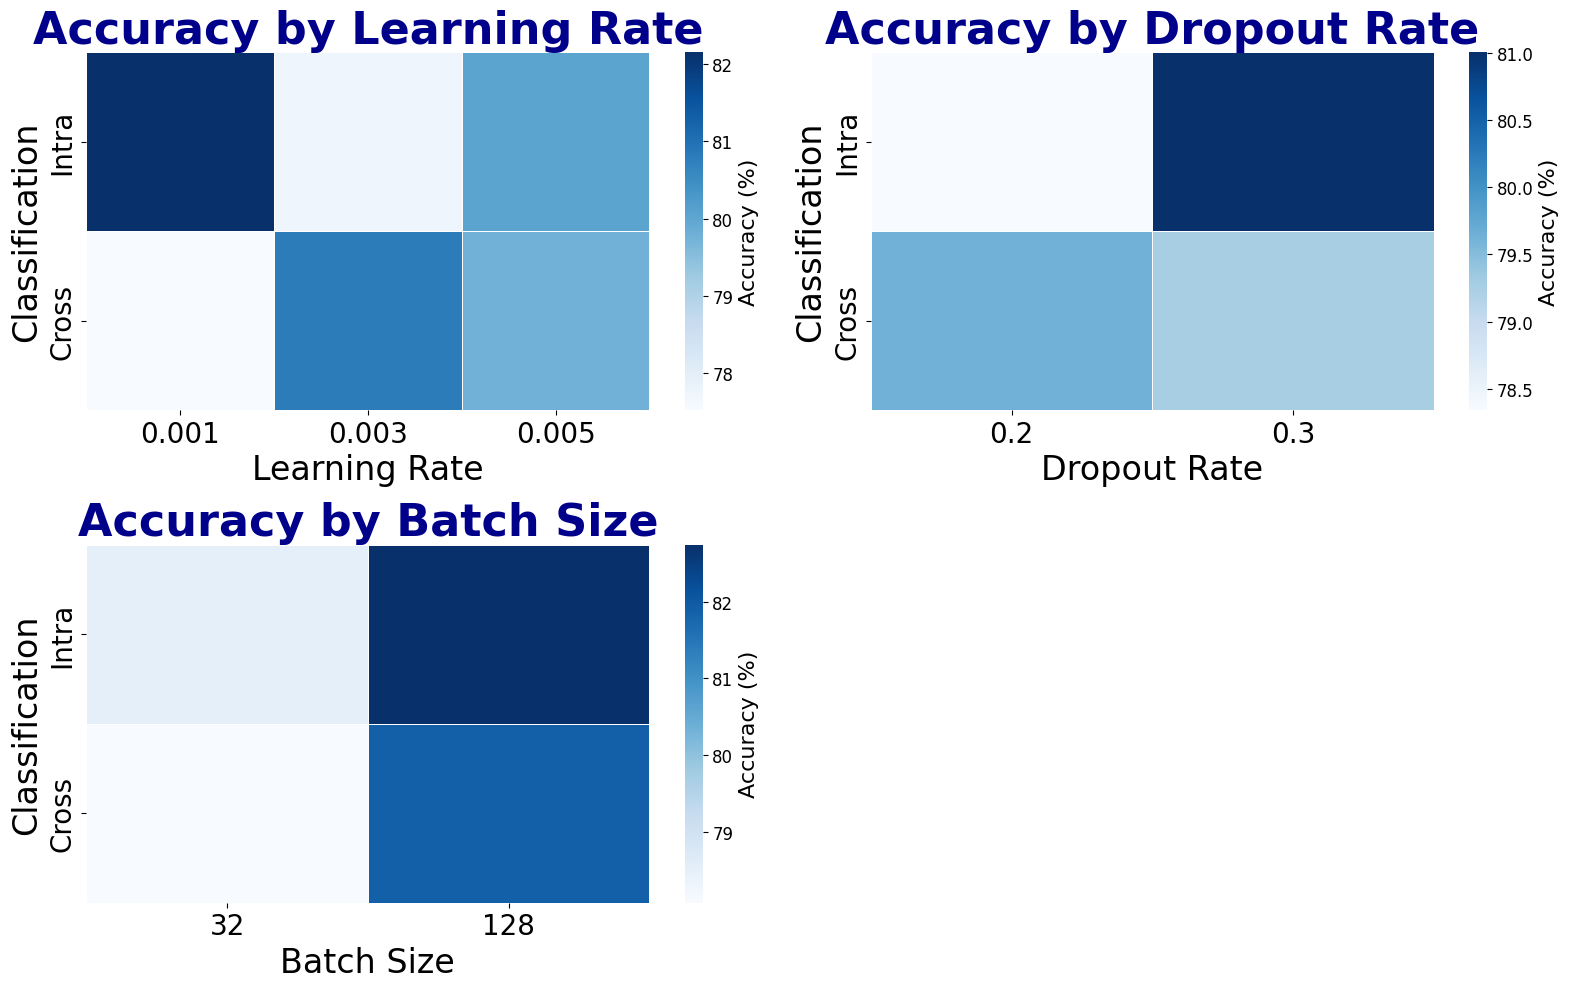

In [14]:
parameters_to_plot = ["learning_rate", "dropout_rate", "batch_size"]
plot_metric_heatmaps_by_parameters(all_metrics_df, parameters_to_plot, metric="accuracy")

# Bar chart (accuracy per task/classification)

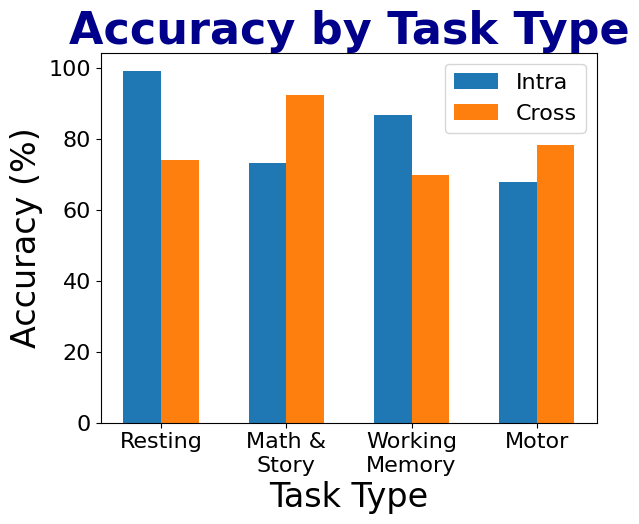

In [32]:
np.random.seed(56)

width = 0.3 # Width of the bars

x = np.arange(4) # Multiply by some value to increase distance between bars
intra = np.random.uniform(60, 100, 4) # 4 accuracy values for intra in order: (resting, math&story, working memory, motor)
cross = np.random.uniform(60, 100, 4) # 4 accuracy values for cross in order: (resting, math&story, working memory, motor)

plt.bar(x-0.5*width, intra, width)
plt.bar(x+0.5*width, cross, width)

plt.title("Accuracy by Task Type", fontsize=32, weight='bold', color='darkblue')
plt.xticks(x, ["Resting", "Math &\nStory", "Working\nMemory", "Motor"])
plt.tick_params(axis="both", labelsize=16)
plt.xlabel("Task Type", fontsize=24)
plt.ylabel("Accuracy (%)", fontsize=24)
plt.legend(["Intra", "Cross"], fontsize=16)
plt.show()